# Gas Sensor Drift Classification

연구 설명·기존 결과 검토는 이 Notebook, 실행 기능은 src/, 검증은 tests/로 분리함. 기존 점수는 저장 CSV에서 읽으며 모델 선정이나 신규 성능 실험을 다시 수행하지 않음. 가스 분류·분포 변화 감지·재학습 후보 관리의 로컬 연구용 프로토타입임.

## 1. 프로젝트 개요

센서 신호로 6종 가스를 구분하고 시간순 일반화 한계를 연구함. UCI Gas Sensor Array Drift Dataset 224, Vergara et al. (2012), DOI:10.24432/C5RP6W. Batch는 순서 정보이며 실제 시각·농도·측정 환경을 임의로 생성하지 않음. Batch9~10과 과거 Validation은 반복 사용한 회고적 자료이며 독립 최종 Test가 아님.

In [1]:
# 프로젝트 루트와 공통 연구 모듈 준비
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src/data.py').exists():
    raise RuntimeError('프로젝트 루트에서 실행 필요')
sys.path.insert(0, str(ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import FEATURES, GASES, duplicate_summary, feature_label
from src import research as study
%matplotlib inline
pd.set_option('display.max_columns', 18)


## 2. 데이터 로딩 및 구조 확인

외부 원본은 읽기만 하며 파일 지문과 구성 확인. 전체13,910행·128특징·6가스·10 Batch. LIBSVM의 정답+명시적1:값~128:값 형식이며 공백/탭 구분을 엄격하게 검사함.

In [2]:
# 원본 데이터와 품질 확인
frame, files = study.study_data()
display(files[['batch', 'samples', 'features', 'missing_nan', 'infinite']])
display(frame[['batch', 'gas', 'row_id', *FEATURES[:3]]].head())
groups, duplicate_checks = duplicate_summary(frame)
print('결측:', int(frame[FEATURES].isna().sum().sum()), '무한대:', int(np.isinf(frame[FEATURES]).sum().sum()))
print('중복 검사:', duplicate_checks)
assert frame.row_id.is_unique and len(frame) == 13910


,batch,samples,features,missing_nan,infinite
0,1,445,128,0,0
1,2,1244,128,0,0
2,3,1586,128,0,0
3,4,161,128,0,0
4,5,197,128,0,0
5,6,2300,128,0,0
6,7,3613,128,0,0
7,8,294,128,0,0
8,9,470,128,0,0
9,10,3600,128,0,0


,batch,gas,row_id,f001,f002,f003
0,1,1,b01_r00001,15596.1621,1.868245,2.371604
1,1,1,b01_r00002,26402.0704,2.532401,5.411209
2,1,1,b01_r00003,42103.5820,3.454189,8.198175
3,1,1,b01_r00004,42825.9883,3.451192,12.113940
4,1,1,b01_r00005,58151.1757,4.194839,11.455096


결측: 0 무한대: 0
중복 검사: {'feature_duplicate_extra': 0, 'feature_duplicate_rows': 0, 'labeled_duplicate_extra': 0, 'conflicting_label_groups': 0, 'cross_batch_duplicate_groups': 0}


## 3. 탐색적 데이터 분석(EDA)

16개 센서별8개 특징은 기존 feature_label 정의를 재사용함. 센서1 히트맵은 f001~f008만 다루며 전체128개 상관행렬이 아님. 가스·Batch 구성 차이를 센서 노후화의 인과효과로 해석하지 않음.

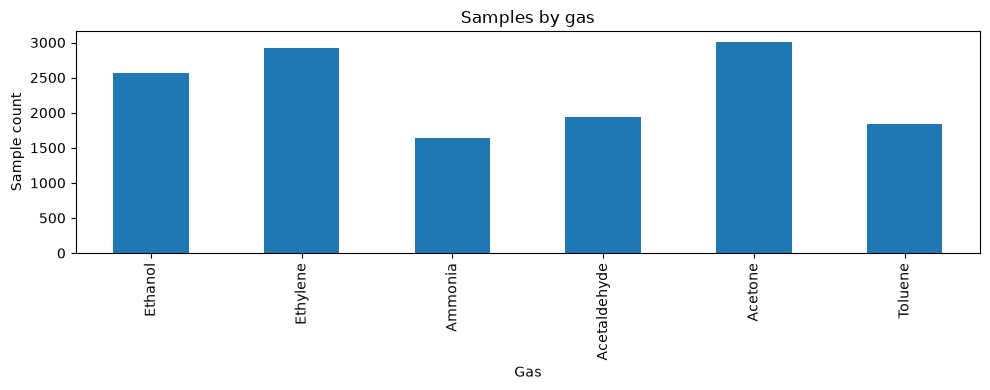

gas,Ethanol,Ethylene,Ammonia,Acetaldehyde,Acetone,Toluene
batch,,,,,,
1,90,98,83,30,70,74
2,164,334,100,109,532,5
3,365,490,216,240,275,0
4,64,43,12,30,12,0
5,28,40,20,46,63,0
6,514,574,110,29,606,467
7,649,662,360,744,630,568
8,30,30,40,33,143,18
9,61,55,100,75,78,101


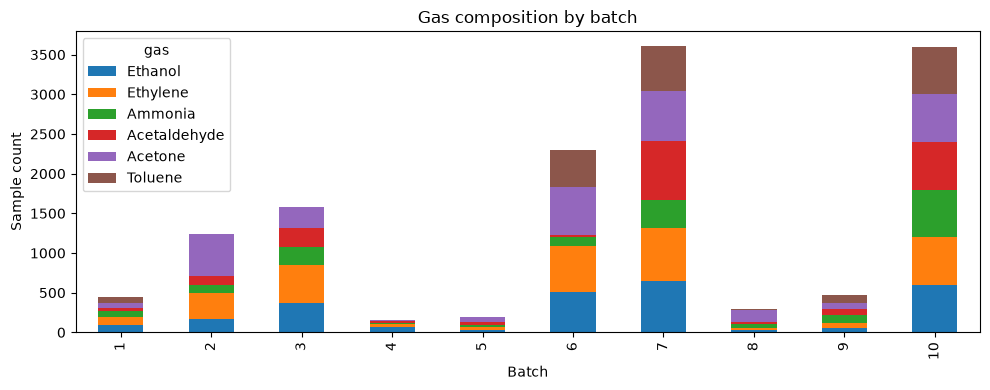

In [3]:
# 가스별·Batch별 표본 수 시각화
gas_counts = frame.gas.value_counts().reindex(GASES).rename(index=GASES)
study.bar_values(gas_counts, 'Samples by gas', 'Gas', 'Sample count'); plt.show()
batch_gas = pd.crosstab(frame.batch, frame.gas).rename(columns=GASES)
display(batch_gas)
ax = batch_gas.plot.bar(stacked=True, figsize=(10, 4))
ax.set(title='Gas composition by batch', xlabel='Batch', ylabel='Sample count')
plt.tight_layout(); plt.show()


,count,mean,std,min,25%,50%,75%,max
f001,13910.0,50435.066174,69844.785952,-16757.598600,6694.725950,19364.439350,63104.837125,670687.347700
f002,13910.0,6.638156,13.486391,0.088287,2.284843,3.871227,8.400619,1339.879283
f009,13910.0,57340.104585,64045.265134,-16119.460900,13287.301875,37764.263200,70300.782575,502202.812500
f017,13910.0,16204.100366,11419.266483,-22110.726500,7465.667125,14545.048600,23046.619475,71110.771500


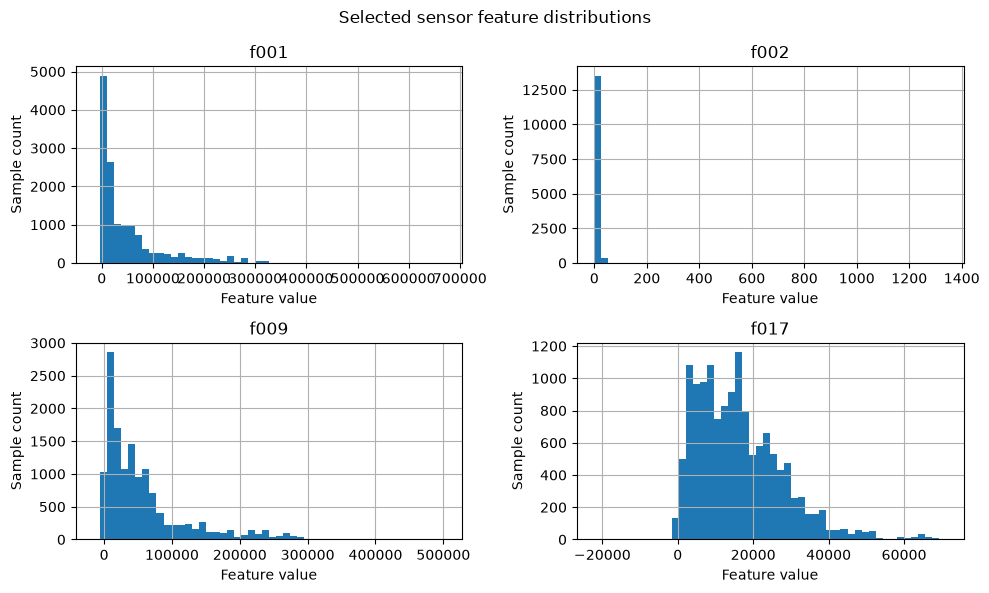

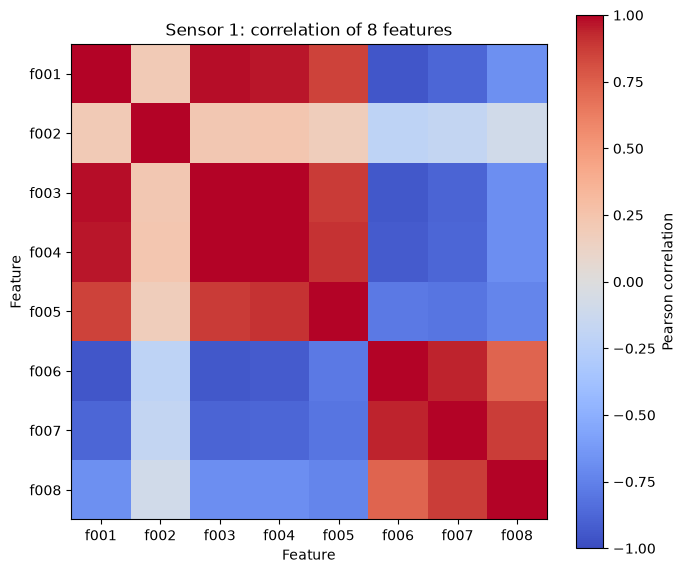

,feature,definition
0,f001,f001: S1 delta_R
1,f002,f002: S1 normalized_R
2,f003,f003: S1 EMA_rise_0.001
3,f004,f004: S1 EMA_rise_0.01
4,f005,f005: S1 EMA_rise_0.1
5,f006,f006: S1 EMA_decay_0.001
6,f007,f007: S1 EMA_decay_0.01
7,f008,f008: S1 EMA_decay_0.1


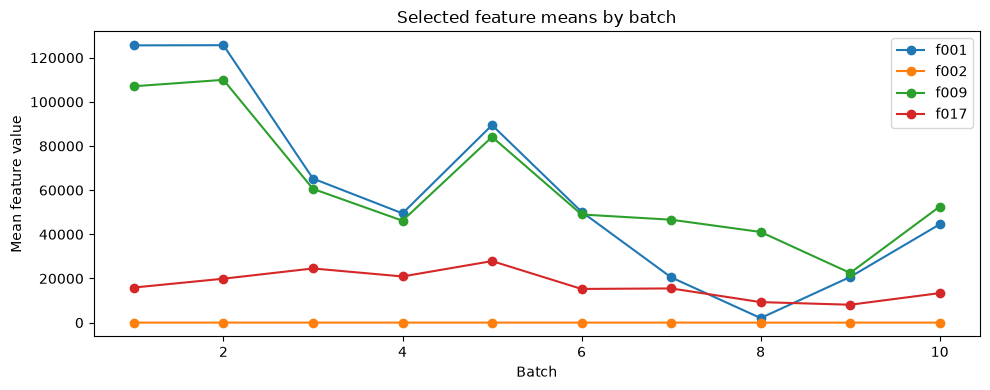

In [4]:
# 주요 특징 분포·센서 내 상관·Batch별 평균 확인
selected = ['f001', 'f002', 'f009', 'f017']
display(frame[selected].describe().T)
frame[selected].hist(bins=50, figsize=(10, 6))
for ax in plt.gcf().axes:
    ax.set(xlabel='Feature value', ylabel='Sample count')
plt.suptitle('Selected sensor feature distributions'); plt.tight_layout(); plt.show()
study.sensor_correlation(frame, sensor=1); plt.show()
display(pd.DataFrame({'feature': FEATURES[:8], 'definition': [feature_label(i) for i in range(1, 9)]}))
ax = frame.groupby('batch')[selected].mean().plot(marker='o', figsize=(10, 4))
ax.set(title='Selected feature means by batch', xlabel='Batch', ylabel='Mean feature value')
plt.tight_layout(); plt.show()


탐색 PCA 분산 설명 비율: [0.53515135 0.15040059]


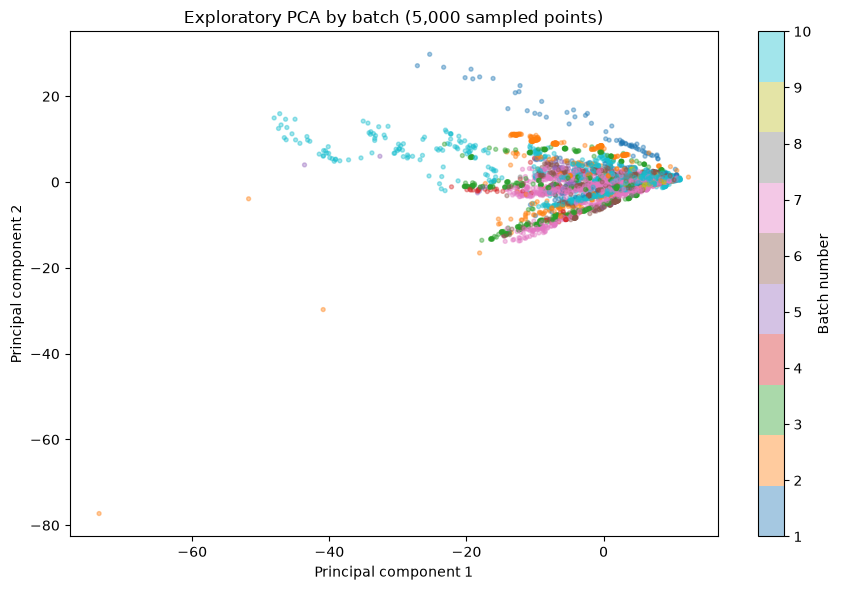

In [5]:
# 탐색 목적 PCA이며 모델 학습에 사용하지 않음
figure, variance = study.exploratory_pca(frame)
print('탐색 PCA 분산 설명 비율:', variance)
plt.show()


## 4. 전처리

공식 파이프라인은 Train 중앙값 처리→StandardScaler→RBF SVM. Train은 Batch1~6의5,933행이며 전처리는 이 자료에서만 fit됨. 위 EDA PCA·스케일러는 시각화용으로만 생성하고 저장·재사용하지 않음. batch·gas·row_id는 분류 입력에서 제외함.

In [6]:
# 실제 저장 모델의 전처리·입력 확인
from src.webapp.service import load_models, MODEL_SHA, DETECTOR_SHA
models = load_models()
print(models.classifier)
print('SVM 설정:', models.classifier.named_steps['classifier'].get_params())
print('입력 특징 수:', len(models.classifier.feature_names_in_))
assert list(models.classifier.feature_names_in_) == FEATURES
assert models.classifier.named_steps['scaler'].n_samples_seen_ == 5933


Pipeline(steps=[('imputer',
                 SimpleImputer(keep_empty_features=True, strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 SVC(cache_size=512, class_weight='balanced', probability=False,
                     random_state=42))])
SVM 설정: {'C': 1.0, 'break_ties': False, 'cache_size': 512, 'class_weight': 'balanced', 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': 42, 'shrinking': True, 'tol': 0.001, 'verbose': False}
입력 특징 수: 128


## 5. 기본 분류 모델 실험

LR·RF·SVM의 기존 동일 분할 결과를 읽음. 랜덤 Train60%/Validation20%/Test20%, random_state42. 시간순 초기 실험은B_early(Train1, Validation2, 평가3~10), B_history(Train1~3, Validation4, 평가5~10). 서로 다른 평가 자료의 단순 우열과 인과효과를 주장하지 않음. macro_f1은 해당 평가에 존재하는 클래스, macro_f1_fixed6은 고정6종 평균이므로 구분해서 읽음.

,experiment,model,n,accuracy,macro_precision,macro_recall,macro_f1,macro_f1_fixed6,weighted_f1
0,A_random,LogisticRegression,2782,0.992092,0.991992,0.991802,0.991890,0.991890,0.992092
1,A_random,RandomForest,2782,0.994608,0.995192,0.994145,0.994656,0.994656,0.994608
2,A_random,SVM_RBF,2782,0.984903,0.986080,0.983164,0.984534,0.984534,0.984894
3,B_early,LogisticRegression,12221,0.442435,0.455943,0.410090,0.313766,0.313766,0.333722
4,B_early,RandomForest,12221,0.435398,0.409231,0.412736,0.327355,0.327355,0.341458
5,B_early,SVM_RBF,12221,0.375665,0.410063,0.362171,0.292938,0.292938,0.300258
6,B_history,LogisticRegression,10474,0.619725,0.545807,0.599627,0.549265,0.549265,0.560704
7,B_history,RandomForest,10474,0.509261,0.449620,0.495903,0.459488,0.459488,0.477081
8,B_history,SVM_RBF,10474,0.603972,0.606918,0.606334,0.578771,0.578771,0.576568


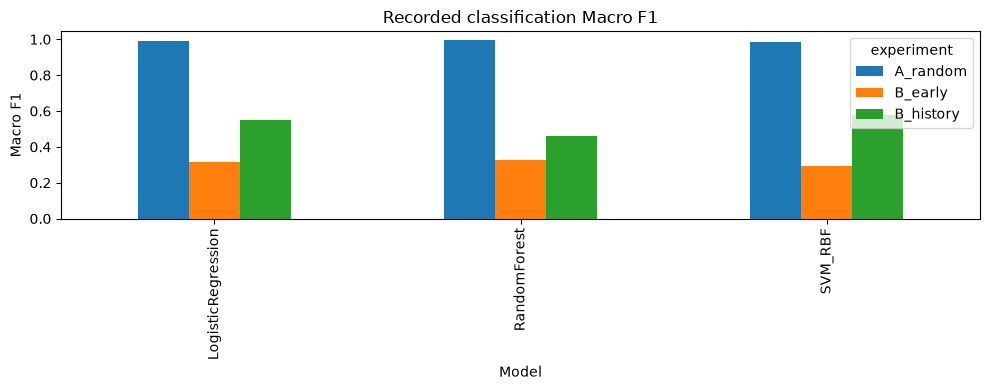

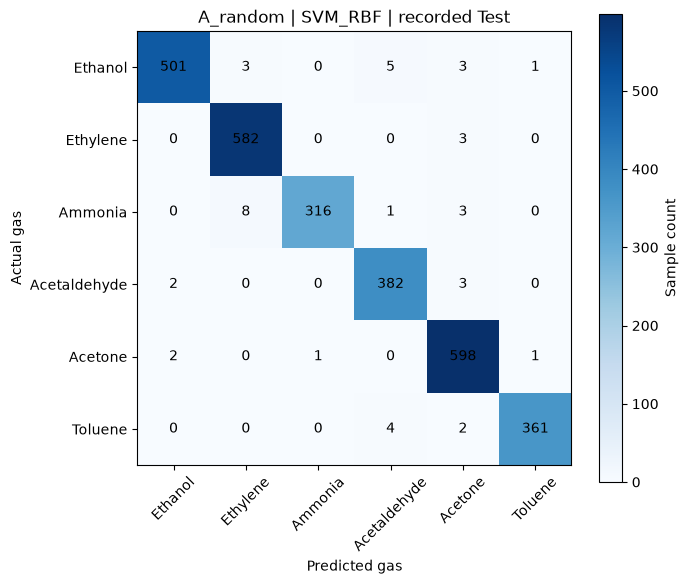

In [7]:
# 기존 지표와 혼동행렬 재표시
baseline = study.comparison_table()
display(baseline)
plot = baseline.pivot(index='model', columns='experiment', values='macro_f1')
study.bar_values(plot, 'Recorded classification Macro F1', 'Model', 'Macro F1'); plt.show()
study.stored_confusion(); plt.show()


**선택 재현 코드(기본 미실행):** 아래 분기는 기존 training_config.json과 공통 분할·파이프라인 함수를 사용함. 21단계에서는 새 학습 결과를 만들지 않기 위해 False로 유지함. 사용자가 True로 바꾸면 새로 계산한 메모리상의 별도 재현 결과이며, 기존 CSV·모델·운영 포인터를 수정하지 않음. 기존 연구 결과를 이번에 재학습으로 재현 완료했다고 주장하지 않음.

In [8]:
# 명시적으로 선택한 경우에만 기존 랜덤 분할 학습 재현
RUN_BASELINE_REPLAY = False
if RUN_BASELINE_REPLAY:
    from src.train_models import make_splits, make_pipeline, evaluate
    from threadpoolctl import threadpool_limits
    settings = json.loads((ROOT / 'training_config.json').read_text(encoding='utf-8'))
    split = make_splits(frame, settings)['A_random']
    training = frame.iloc[split['train']]
    validation = frame.iloc[split['validation']]
    replay_rows = []
    with threadpool_limits(limits=1):
        for family in settings['models']:
            pipeline = make_pipeline(family, settings)
            # 전처리와 분류기는 Train에만 적합
            pipeline.fit(training[FEATURES], training.gas)
            metric, _, _ = evaluate(validation.gas, pipeline.predict(validation[FEATURES]))
            replay_rows.append({'model': family, **metric})
    display(pd.DataFrame(replay_rows))
else:
    print('선택 재학습 분기 미실행. 기존 결과는 위 CSV에서 그대로 조회함.')


선택 재학습 분기 미실행. 기존 결과는 위 CSV에서 그대로 조회함.


## 6. 시간순 검증

6단계: Train1~6 / Validation7~8 / 탐색 평가9~10. 반복 검증 A:Train1~3→6, B:Train1~6→7, C:Train1~7→8. 학습 구간이 겹치므로 독립 반복 표본이 아님. Batch8 Toluene18개 등 support 차이와 클래스 누락을 함께 검토함.

,trial_id,family,condition,group,partition,scope,batch,n,accuracy,...,missing_classes,toluene_recall,toluene_f1,toluene_support,acetaldehyde_recall,acetaldehyde_f1,acetaldehyde_support,min_class_recall,other_four_f1
48,B_RF_balanced,RandomForest,B,weight,validation,pooled,0,3907,0.758126,...,NaN,0.687713,0.705779,586,0.177606,0.298056,777,0.177606,0.838165
49,B_RF_balanced,RandomForest,B,weight,validation,batch,7,3613,0.758373,...,NaN,0.709507,0.727437,568,0.184140,0.307520,744,0.184140,0.839095
50,B_RF_balanced,RandomForest,B,weight,validation,batch,8,294,0.755102,...,NaN,0.000000,0.000000,18,0.030303,0.057143,33,0.000000,0.842977
51,B_RF_balanced,RandomForest,B,weight,evaluation,pooled,0,4070,0.442998,...,NaN,0.176890,0.291765,701,0.075556,0.122156,675,0.075556,0.508991
52,B_RF_balanced,RandomForest,B,weight,evaluation,batch,9,470,0.591489,...,NaN,0.000000,0.000000,101,0.000000,0.000000,75,0.000000,0.775058
53,B_RF_balanced,RandomForest,B,weight,evaluation,batch,10,3600,0.423611,...,NaN,0.206667,0.332886,600,0.085000,0.134211,600,0.085000,0.478348
54,B_SVM_balanced,SVM_RBF,B,weight,validation,pooled,0,3907,0.896852,...,NaN,0.890785,0.886248,586,0.629344,0.771902,777,0.629344,0.931067
55,B_SVM_balanced,SVM_RBF,B,weight,validation,batch,7,3613,0.894824,...,NaN,0.894366,0.888889,568,0.615591,0.762063,744,0.615591,0.932675
56,B_SVM_balanced,SVM_RBF,B,weight,validation,batch,8,294,0.921769,...,NaN,0.777778,0.800000,18,0.939394,0.953846,33,0.725000,0.907124
57,B_SVM_balanced,SVM_RBF,B,weight,evaluation,pooled,0,4070,0.570270,...,NaN,0.462197,0.460227,701,0.186667,0.304716,675,0.186667,0.646750


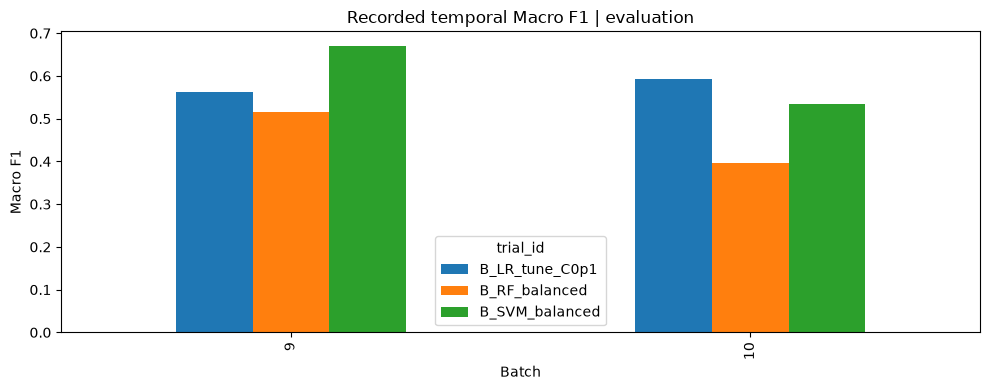

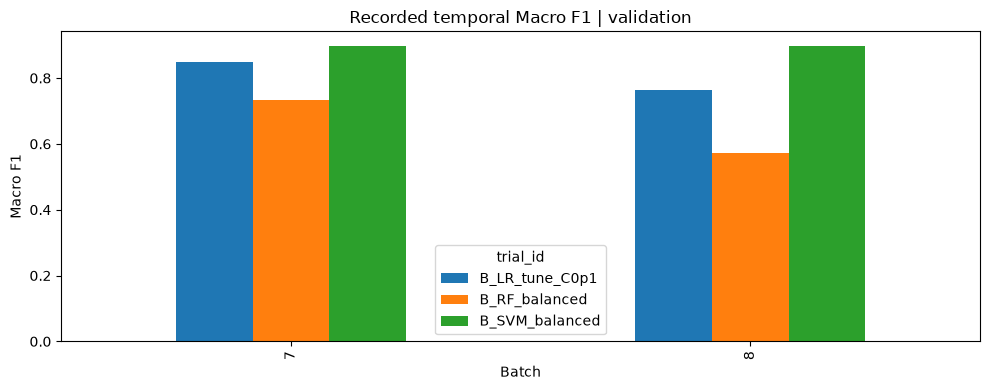

In [9]:
# 기존 시간순 점수와 클래스별 성능 확인
temporal = study.result_table('temporal_expansion/metrics.csv')
representatives = ['B_LR_tune_C0p1', 'B_RF_balanced', 'B_SVM_balanced']
display(temporal[temporal.trial_id.isin(representatives)])
batch_scores = temporal[(temporal.trial_id.isin(representatives)) & (temporal.scope == 'batch')]
for part, rows in batch_scores.groupby('partition'):
    pivot = rows.pivot(index='batch', columns='trial_id', values='macro_f1')
    study.bar_values(pivot, 'Recorded temporal Macro F1 | ' + part, 'Batch', 'Macro F1'); plt.show()


,partition,batch,gas,support,precision,recall,f1
330,validation,7,Ethanol,649,0.970105,1.000000,0.984825
331,validation,7,Ethylene,662,0.791866,1.000000,0.883845
332,validation,7,Ammonia,360,0.987915,0.908333,0.946454
333,validation,7,Acetaldehyde,744,1.000000,0.615591,0.762063
334,validation,7,Acetone,630,0.845430,0.998413,0.915575
335,validation,7,Toluene,568,0.883478,0.894366,0.888889
336,validation,8,Ethanol,30,0.789474,1.000000,0.882353
337,validation,8,Ethylene,30,1.000000,0.933333,0.965517
338,validation,8,Ammonia,40,0.966667,0.725000,0.828571
339,validation,8,Acetaldehyde,33,0.968750,0.939394,0.953846


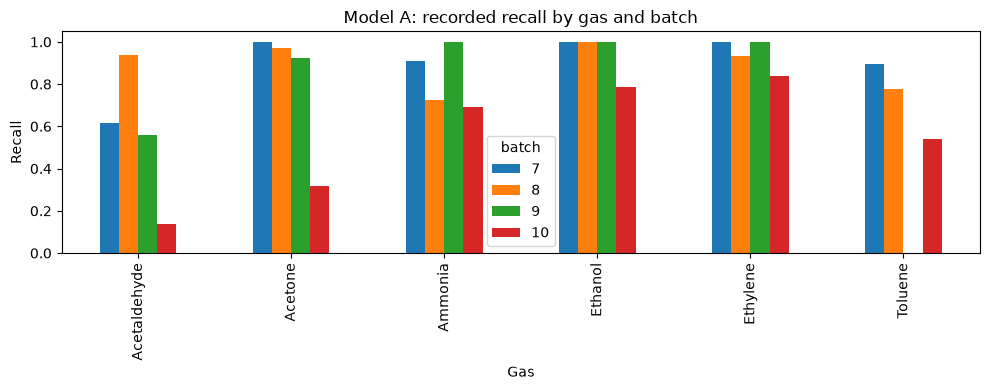

In [10]:
# 기존 Model A의6종 Recall과 support를 Batch별로 확인
gas_scores = study.result_table('temporal_expansion/per_class_metrics.csv')
gas_scores = gas_scores[(gas_scores.trial_id == 'B_SVM_balanced') & (gas_scores.scope == 'batch')]
display(gas_scores[['partition', 'batch', 'gas', 'support', 'precision', 'recall', 'f1']])
recall_table = gas_scores.pivot(index='gas', columns='batch', values='recall')
study.bar_values(recall_table, 'Model A: recorded recall by gas and batch', 'Gas', 'Recall')
plt.show()


## 7. 공식 모델 선정

6단계 Validation Batch별 Macro F1 동일 가중 평균을 주 기준으로 SVM 후보를 고정함. 후속 개선에서 일관된6종 균형 개선을 확보하지 못해 공식 Model A를 유지함. 공식 모델이라는 명칭은 서비스 기준 모델을 뜻하며 독립 최종 성능 인증을 뜻하지 않음.

In [11]:
# 원본 선정 근거와 과거 예측200개 재현 확인 (Batch7)
selection = study.result_json('temporal_expansion/selection_frozen.json')
print('기존 우선 후보:', selection['priority_candidate'])
print('기존 선정 기준:', selection['primary_metric'])
past = study.result_table('nonlinear_feature_transformation/predictions.csv')
past = past[(past.fold == 'B') & (past.method == 'baseline')].set_index('row_id')
sample = frame[frame.batch.eq(7)].head(200)
np.testing.assert_array_equal(models.classifier.predict(sample[FEATURES]), past.loc[sample.row_id, 'y_pred'])
print('Batch7 기존200개 예측 일치. 신규 Batch9~10 성능 계산 아님.')


기존 우선 후보: B_SVM_balanced
기존 선정 기준: val_equal_batch_macro_f1
Batch7 기존200개 예측 일치. 신규 Batch9~10 성능 계산 아님.


## 8. 성능 개선 및 적응 실험

5단계 엄격한 과거Test 제외 시 Train370개로 제한됨. 6단계부터 과거Test를 개발 자료로 재지정한 회고적 실험임. 특징 선택·LR/RF/SVM·가중치·시기 구성·비선형 변환·시기별 앙상블·HGB·소량 라벨 적응의 기존 결과를 원문 CSV로 확인함. Toluene–Acetaldehyde 성능 상충과 일부 Batch Recall0 문제를 숨기지 않음. 표본 수·가스 구성·수집 시기가 동시에 변하므로 데이터 양만의 효과라고 단정하지 않음. 각 표의 분할·가스 support·지표 정의가 다르면 직접 합쳐 순위를 만들지 않음.

In [12]:
# 기존 실험 표를 출처와 함께 조회하며 새 실험 점수는 만들지 않음
historical_sources = {'5 제한 학습': 'model_improvement/metrics.csv', '8 특징 선택·반복 검증': 'temporal_robustness/fold_metrics.csv', '9 가중치': 'temporal_weighting/fold_metrics.csv', '10 사후 일반화 검토': 'temporal_generalization_validation/evaluation_metrics.csv', '12 학습 시기 구성': 'temporal_representativeness_control/historical_metrics.csv', '13 가스별 시기 균형': 'gas_specific_temporal_balancing/historical_metrics.csv', '14 비선형 변환': 'nonlinear_feature_transformation/fold_metrics.csv', '15 시기별 SVM': 'temporal_svm_ensemble/fold_metrics.csv', '16 HGB': 'hgb_algorithm_comparison/fold_metrics.csv', '17 소량 라벨 적응': 'temporal_calibration/metrics.csv'}
for label, source in historical_sources.items():
    print('\n', label, '| 원본:', source)
    table = study.result_table(source)
    print('전체 기록 행 수:', len(table))
    display(table.head(12))



 5 제한 학습 | 원본: model_improvement/metrics.csv
전체 기록 행 수: 168


,trial_id,family,group,partition,scope,batch,n,accuracy,macro_precision,...,macro_precision_fixed6,macro_recall_fixed6,macro_f1_fixed6,missing_classes,toluene_recall,toluene_f1,toluene_support,other_five_macro_f1,min_class_recall
0,LR_base,LogisticRegression,baseline,validation,pooled,0,1022,0.858121,0.685432,...,0.685432,0.803199,0.726362,NaN,1.000000,0.727273,4,0.726180,0.000000
1,LR_base,LogisticRegression,baseline,validation,batch,2,1022,0.858121,0.685432,...,0.685432,0.803199,0.726362,NaN,1.000000,0.727273,4,0.726180,0.000000
2,LR_base,LogisticRegression,baseline,test,pooled,0,12221,0.461664,0.469844,...,0.469844,0.434036,0.336463,NaN,0.027366,0.050500,1754,0.393656,0.000556
3,LR_base,LogisticRegression,baseline,test,batch,3,1586,0.716267,0.666826,...,0.555689,0.531457,0.517364,Toluene,NaN,NaN,0,0.620836,0.000000
4,LR_base,LogisticRegression,baseline,test,batch,4,161,0.534161,0.419034,...,0.349195,0.391493,0.352497,Toluene,NaN,NaN,0,0.422997,0.000000
5,LR_base,LogisticRegression,baseline,test,batch,5,197,0.385787,0.288245,...,0.240204,0.402381,0.269302,Toluene,NaN,NaN,0,0.323163,0.000000
6,LR_base,LogisticRegression,baseline,test,batch,6,2300,0.462174,0.264864,...,0.264864,0.327708,0.231918,NaN,0.004283,0.008493,467,0.276603,0.000000
7,LR_base,LogisticRegression,baseline,test,batch,7,3613,0.433158,0.243849,...,0.243849,0.452993,0.307664,NaN,0.000000,0.000000,568,0.369197,0.000000
8,LR_base,LogisticRegression,baseline,test,batch,8,294,0.333333,0.539958,...,0.539958,0.497643,0.305002,NaN,0.055556,0.105263,18,0.344949,0.000000
9,LR_base,LogisticRegression,baseline,test,batch,9,470,0.421277,0.291889,...,0.291889,0.445455,0.317084,NaN,0.000000,0.000000,101,0.380501,0.000000



 8 특징 선택·반복 검증 | 원본: temporal_robustness/fold_metrics.csv
전체 기록 행 수: 66


,n,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_precision_fixed6,macro_recall_fixed6,macro_f1_fixed6,...,acetaldehyde_support,min_class_recall,other_four_f1,config_id,fold,fit_seconds,predict_seconds,n_features,zero_recall_classes
0,2300,0.781304,0.656062,0.806292,0.664224,0.763180,0.656062,0.806292,0.664224,...,29,0.000000,0.967707,LR_all,A,0.510415,0.009902,128,6.0
1,2300,0.781304,0.656832,0.806390,0.664568,0.763784,0.656832,0.806390,0.664568,...,29,0.000000,0.968397,LR_variance,A,0.461173,0.010185,115,6.0
2,2300,0.780000,0.828512,0.801926,0.678328,0.781280,0.828512,0.801926,0.678328,...,29,0.049251,0.967808,LR_correlation,A,0.244632,0.009383,73,NaN
3,2300,0.695217,0.774956,0.754448,0.618735,0.733002,0.774956,0.754448,0.618735,...,29,0.070664,0.873556,LR_stability64,A,0.211933,0.007575,64,NaN
4,2300,0.622609,0.559536,0.694942,0.533138,0.657264,0.559536,0.694942,0.533138,...,29,0.000000,0.780607,LR_kbest32,A,0.178693,0.007237,32,6.0
5,2300,0.718696,0.610738,0.771729,0.613679,0.729951,0.610738,0.771729,0.613679,...,29,0.000000,0.897612,LR_kbest64,A,0.238721,0.007250,64,6.0
6,2300,0.713913,0.613689,0.753755,0.615215,0.703248,0.613689,0.753755,0.615215,...,29,0.000000,0.896247,RF_all,A,0.432519,0.035686,128,6.0
7,2300,0.706522,0.606690,0.754656,0.608802,0.698167,0.606690,0.754656,0.608802,...,29,0.000000,0.886434,RF_variance,A,0.384367,0.035789,115,6.0
8,2300,0.697391,0.622778,0.747281,0.612368,0.693483,0.622778,0.747281,0.612368,...,29,0.000000,0.892958,RF_correlation,A,0.329093,0.043405,73,6.0
9,2300,0.663478,0.559822,0.644934,0.557029,0.681608,0.559822,0.644934,0.557029,...,29,0.000000,0.824519,RF_stability64,A,0.356315,0.045005,64,6.0



 9 가중치 | 원본: temporal_weighting/fold_metrics.csv
전체 기록 행 수: 24


...

,model,fold,batch,role,predict_seconds,n,accuracy,macro_f1,weighted_f1,min_recall,zero_recall,toluene_to_acetaldehyde,acetaldehyde_to_toluene
0,full,A,6,expert,0.203436,2300,0.694783,0.619870,0.702967,0.000000,1,416,0
1,recent,A,6,expert,0.062466,2300,0.669130,0.566089,0.693988,0.000000,1,416,0
2,spread,A,6,expert,0.101976,2300,0.524783,0.510848,0.547361,0.000000,1,416,0
3,oracle,A,6,oracle,0.000000,2300,0.702174,0.624228,0.709285,0.000000,1,416,0
4,full,B,7,expert,0.464231,3613,0.894824,0.896942,0.889471,0.615591,0,0,67
5,recent,B,7,expert,0.111401,3613,0.748685,0.729625,0.731072,0.366197,0,89,60
6,spread,B,7,expert,0.178198,3613,0.779684,0.790581,0.780961,0.353495,0,46,395
7,oracle,B,7,oracle,0.000000,3613,0.913092,0.914589,0.907055,0.623656,0,0,67
8,full,C,8,expert,0.065199,294,0.897959,0.874435,0.896466,0.675000,0,2,0
9,recent,C,8,expert,0.015353,294,0.591837,0.576746,0.606474,0.066667,0,1,0



 16 HGB | 원본: hgb_algorithm_comparison/fold_metrics.csv
전체 기록 행 수: 6


,fold,batch,model,fit_seconds,predict_seconds,n,accuracy,macro_f1,weighted_f1,min_recall,zero_recall,toluene_to_acetaldehyde,acetaldehyde_to_toluene
0,A,6,SVM,0.000000,0.267540,2300,0.694783,0.619870,0.702967,0.000000,1,416,0
1,A,6,HGB,15.996167,0.130861,2300,0.661304,0.579951,0.680838,0.000000,1,448,0
2,B,7,SVM,0.000000,0.475712,3613,0.894824,0.896942,0.889471,0.615591,0,0,67
3,B,7,HGB,18.277240,0.099311,3613,0.717686,0.678437,0.682734,0.177419,0,25,2
4,C,8,SVM,0.000000,0.065985,294,0.897959,0.874435,0.896466,0.675000,0,2,0
5,C,8,HGB,21.849544,0.015769,294,0.833333,0.724564,0.794276,0.033333,0,4,1



 17 소량 라벨 적응 | 원본: temporal_calibration/metrics.csv
전체 기록 행 수: 48


,fold,seed,rate,scope,target_batch,calibration_n,train_n,n,accuracy,macro_f1,weighted_f1,min_recall,zero_recall,toluene_to_acetaldehyde,acetaldehyde_to_toluene,fit_seconds,predict_seconds
0,A,11,0,evaluation,6,0,3275,1150,0.695652,0.617114,0.703493,0.000000,1,209,0,0.000000,0.098915
1,A,11,0,regression,6,0,3275,358,0.935754,0.942497,0.936342,0.855263,0,0,0,0.000000,0.030351
2,A,11,5,evaluation,6,115,3390,1150,0.910435,0.910251,0.913619,0.808581,0,0,0,0.234323,0.116305
3,A,11,5,regression,6,115,3390,358,0.941341,0.947892,0.942029,0.855263,0,0,0,0.234323,0.032157
4,A,11,10,evaluation,6,230,3505,1150,0.945217,0.933537,0.946401,0.872727,0,0,0,0.221803,0.107873
5,A,11,10,regression,6,230,3505,358,0.941341,0.947892,0.942029,0.855263,0,0,0,0.221803,0.033065
6,A,11,20,evaluation,6,460,3735,1150,0.950435,0.941087,0.950717,0.872727,0,0,0,0.203006,0.114350
7,A,11,20,regression,6,460,3735,358,0.941341,0.947892,0.942029,0.855263,0,0,0,0.203006,0.036381
8,A,23,0,evaluation,6,0,3275,1150,0.683478,0.614048,0.693232,0.000000,1,208,0,0.000000,0.091347
9,A,23,0,regression,6,0,3275,358,0.935754,0.942497,0.936342,0.855263,0,0,0,0.000000,0.030544


학습 재실행은 이번 정리에서 수행하지 않음. 기존 make_splits/make_pipeline/evaluate 등 공통 계산과 모델 파일·고정 설정은 유지함. 저장 지표와 예측에서 결과를 재검사할 수 있으나, 보고서 생성·이력 동결·과거 파일 덮어쓰기까지 섞여 있던 옛 일괄CLI는 제거함. 따라서 해당CLI를 통한1~18단계 일괄 실행은 지원하지 않으며, 과거 전 실험의 재학습을 완료한 것으로 표현하지 않음.

분류 실패의 관찰과 해석을 구분함. 아래 표는11단계에서 기록한 가설별 사실·추정·미확인 사항이며 새로운 실험 결과가 아님. 가스 간 특징 공간 중첩은 화학적 유사성의 증명이 아니며, 농도·환경·실제 센서 노후화의 독립 효과도 확정할 수 없음.

In [13]:
# 기존 실패 원인 가설의 확인 수준 조회
display(study.result_table('toluene_failure_deep_diagnostic/hypothesis_evidence.csv'))


,hypothesis,assessment,observed,interpretation,unresolved,next_test
0,1. 시기별 대표성 부족,일부 부합,B의 Batch9 Toluene은 다른 가스가 더 가까운 표본 100/101. Tr...,관측된 미래 Toluene과 학습 Toluene의 국소 대표성 부족과 양립함. 전체...,농도·환경·세션 메타데이터 없이 대표성의 물리적 원인과 인과 기여도 미확인.,동일 가스별 표본 예산을 맞춘 시기 분산/집중 대조를 과거 시간순 창에서 사전 설계.
1,2. 다른 가스와의 특징 중첩,관찰 결과와 부합,B Batch9 Toluene의 Ac 대 T 이진 판별이 Ac를 지지한 표본 100...,고정 표준화·관측 특징 공간에서 혼동 영역과 양립. 최근접 구조는 SVM의 직접 원...,화학적 유사성·실제 확률분포 중첩·라벨 오류는 이 결과만으로 확정 불가.,농도와 환경이 기록된 참조 측정으로 두 가스의 조건별 분리 정도 확인.
2,3. 결정 경계의 변화,관찰 결과와 부합,동일101개에서 A Ethanol101 → B Acetaldehyde96/Ethan...,두 고정 파이프라인의 결정 함수가 달라진 사실은 확인. Batch7의 특정 요소 하...,학습 표본·표준화 통계·클래스 가중치가 함께 바뀌어 독립 효과 분리 불가. 수치 g...,향후 전처리 고정/자료 범위/가중치의 작은 통제 대조. 기존9–10을 선정에 사용하...
3,4. 특정 센서 특징의 변화,일부 부합,B 기준 Batch9 Toluene 정규화 분포 차이 1위 센서 S5: 8특징 평균...,단변량 이동과 특징 조합·상관 변화는 관찰. 사후 순위는 분류기 중요도나 센서 고장...,"어떤 센서가 오류에 필요·충분한지, 드리프트·농도·환경 중 원인은 미확인.",과거 Train 내부만으로 센서 묶음 안정성 기준을 정한 뒤 제한적 제거/보정 대조...


## 9. 분포 변화 감지

고정 RFF-MMD²는 기준의 커널 특징 평균과100행 창 평균의 제곱 거리. 기준2,966행 / 산정1,483행 / 내부평가1,484행은 Batch1~6에서 분리함. 기존 임계값0.00825701197565701을 유지하고 재산정하지 않음. 정답은 감지기 적합·임계값 입력이 아니며 사후 해석용임. 가스 구성·창 순서도 점수에 영향을 주므로 실제 노후화·고장·분류 오류율과 구분함.

,partition,input_rows,windows,valid_windows,invalid_windows,excluded_tail_rows,mean_score,median_score,max_score,alert_windows,alert_rate,threshold
0,calibration,1483,14,14,0,83,0.004477,0.004067,0.008314,1,0.071429,0.008257
1,internal,1484,14,14,0,84,0.003143,0.002593,0.008346,1,0.071429,0.008257
2,batch7,3613,36,36,0,13,0.100152,0.084069,0.256697,36,1.000000,0.008257
3,batch8,294,2,2,0,94,0.228156,0.228156,0.305474,2,1.000000,0.008257


,method,seed,target,source,windows,mean_score,alert_rate
0,original,0,7,target,36,0.100152,1.000000
1,shuffle_all,42,7,target,36,0.040614,1.000000
2,shuffle_fixed_rows,42,7,target,36,0.040406,1.000000
3,shuffle_all,43,7,target,36,0.040922,1.000000
4,shuffle_fixed_rows,43,7,target,36,0.040845,1.000000
5,shuffle_all,44,7,target,36,0.040627,1.000000
6,shuffle_fixed_rows,44,7,target,36,0.040005,1.000000
7,shuffle_all,45,7,target,36,0.040583,1.000000
8,shuffle_fixed_rows,45,7,target,36,0.040477,1.000000
9,shuffle_all,46,7,target,36,0.040678,1.000000


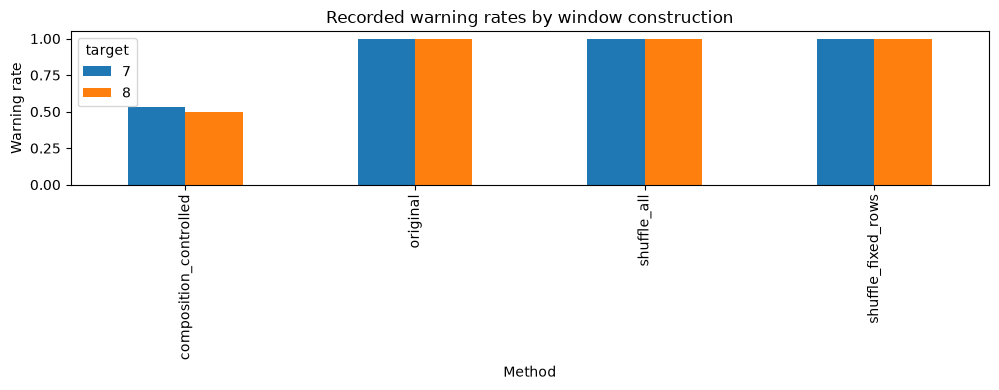

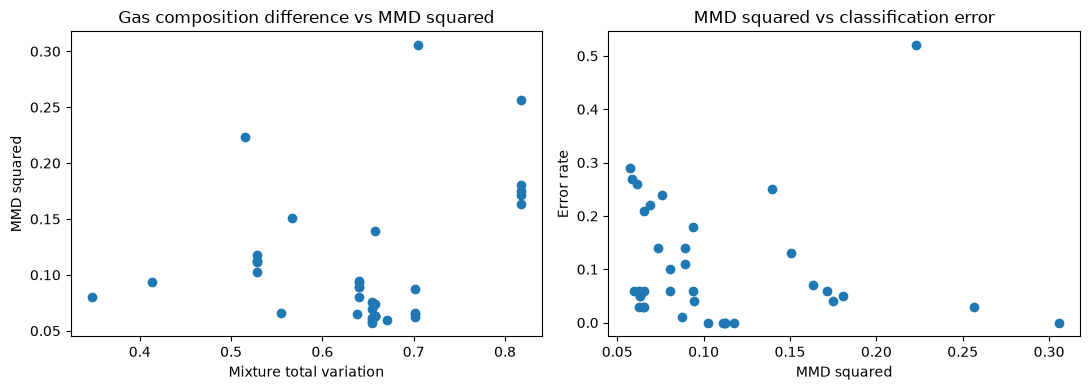

In [14]:
# 고정 감지 결과와 창 구성 민감도 기록 재표시
display(study.result_table('drift_detection/partition_summary.csv'))
sensitivity = study.result_table('drift_detection_sensitivity/condition_summary.csv')
display(sensitivity[['method', 'seed', 'target', 'source', 'windows', 'mean_score', 'alert_rate']])
summary = sensitivity.groupby(['method', 'target']).alert_rate.mean().unstack('target')
study.bar_values(summary, 'Recorded warning rates by window construction', 'Method', 'Warning rate'); plt.show()
relationships = study.result_table('drift_detection_sensitivity/existing_window_analysis.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(relationships.mixture_tv, relationships.score)
axes[0].set(title='Gas composition difference vs MMD squared', xlabel='Mixture total variation', ylabel='MMD squared')
error_column = next(c for c in ['error_rate', 'classification_error_rate'] if c in relationships)
axes[1].scatter(relationships.score, relationships[error_column])
axes[1].set(title='MMD squared vs classification error', xlabel='MMD squared', ylabel='Error rate')
plt.tight_layout(); plt.show()


## 10. 재학습 및 모델 관리

20-A: 실제 정답·출처·세션·중복·시간순 분리·불변 등록. 20-B: 기존5,933행+신규Train에서 같은SVM 학습, 같은신규Validation에서 비교, 후보 별도 저장. 20-C: 출처·정답·검증 독립성 수동 근거, Macro F1 비하락, 확인 후 포인터 전환·이력·롤백. 이 Notebook에서는 학습·승인·운영 전환을 호출하지 않음. 합성 Train60/Validation60에서 후보 Macro F1100%는 기능 검사일 뿐 실제 신규 센서 개선이 아님. 현재실제신규데이터성능개선은미검증이며 인증 없는 로컬 프로토타입임.

In [15]:
# 운영 상태 읽기만 수행하며 매니페스트를 변경하지 않음
from src.model_management.registry import ModelRegistry
manager = ModelRegistry()
active = manager.current()
print('현재 운영 모델:', active['model']['name'])
print('운영 버전:', active['version_id'])
print('적용 시각:', active['applied_at_utc'])
assert active['model']['kind'] == 'official'
print('운영 이력 수:', len(manager.read()['events']))


현재 운영 모델: Model A / B_SVM_balanced
운영 버전: version_5367627123934f7cbf0dcc65e78fe53e
적용 시각: 2026-10-29T05:00:07.446200+00:00
운영 이력 수: 1


## 11. 최종 결과 및 한계

랜덤 분할의 높은 성능과 미래 Batch 실패는 다른 질문에 대한 결과임. Model A는서비스기준으로유지하며, Toluene·Acetaldehyde의시기별실패와성능상충이남아있음. 분포 변화의 인과 원인을 드리프트 하나로 확정하지 않음. 농도·장비·환경 메타데이터 부족, 반복 사용한 Validation과 Batch9~10의 선택 편향, 작은 클래스 support를 명시함. 실제 신규 시기의 독립 자료와 사전 고정한 검증 원칙이 추가로 필요함. 삭제 보고서의 고유 조건·해석은 research/experiment_conditions.json에 원문 SHA와 함께 이관함. 수치의 직접 근거는 아래 catalog의 기존 CSV/JSON이며 서로 다른 실험 설정을 통합한 점수를 만들지 않음.

In [16]:
# Notebook이 사용하는 연구 근거 목록 확인
display(pd.DataFrame([{'experiment': label, 'source': source} for label, source in historical_sources.items()]))
print('Model A SHA-256:', MODEL_SHA)
print('고정 감지기 SHA-256:', DETECTOR_SHA)
print('신규 모델 학습·운영 모델 변경·임계값 재산정 없음')


,experiment,source
0,5 제한 학습,model_improvement/metrics.csv
1,8 특징 선택·반복 검증,temporal_robustness/fold_metrics.csv
2,9 가중치,temporal_weighting/fold_metrics.csv
3,10 사후 일반화 검토,temporal_generalization_validation/evaluation_...
4,12 학습 시기 구성,temporal_representativeness_control/historical...
5,13 가스별 시기 균형,gas_specific_temporal_balancing/historical_met...
6,14 비선형 변환,nonlinear_feature_transformation/fold_metrics.csv
7,15 시기별 SVM,temporal_svm_ensemble/fold_metrics.csv
8,16 HGB,hgb_algorithm_comparison/fold_metrics.csv
9,17 소량 라벨 적응,temporal_calibration/metrics.csv


Model A SHA-256: 1d6b20c94d1580d799e05ab5a9ce746bdb272d74f70ec2ff964011fffecfde32
고정 감지기 SHA-256: de47661f66c69cdc7553f73acf1df9b721f65771d0301fe69a7a326f814fa4c5
신규 모델 학습·운영 모델 변경·임계값 재산정 없음
